# Lab: Build your first image encoder–decoder

**Time:** 60–90 minutes. **Prerequisites:** Python, tensors, basic convolutions, and gradient descent.

Read [CNN-Based Encoder–Decoder Architectures for Images](../../lectures/encoder_decoder/encoder_decoder.md), especially Sections 2–7.

You will reconstruct handwritten digits using a small convolutional network. Each image is both the input and the target: this training task makes our encoder–decoder an **autoencoder**. Digit labels are not used for training.

By the end, you should be able to:
- implement an encoder, spatial latent representation, and decoder;
- trace `[N, C, H, W]` shapes through downsampling and upsampling;
- train with reconstruction MSE and inspect held-out reconstructions;
- measure latent size and explain the bottleneck trade-off.

Complete the four TODO sections. Data loading, plotting, and evaluation are provided. TODO cells intentionally raise `NotImplementedError` until you implement them. Run cells in order.

## 1. Set up and load data (10 minutes)
Use a Python 3 notebook kernel. If needed, uncomment the installation cell, run it once, and restart the kernel. A GPU is optional. The first dataset load needs internet access; later runs use the local cache. `ToTensor()` scales MNIST pixels to `[0, 1]`; do not apply mean/std normalization for this lab.

In [1]:
# %pip install torch torchvision matplotlib

C:\Users\anshu\AppData\Local\Programs\Python\Python310\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Device: cuda
Batch: (64, 1, 28, 28) Pixel range: 0.0 1.0


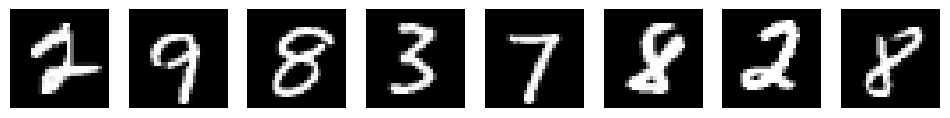

In [2]:
import torch
from torch import nn
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms
import matplotlib.pyplot as plt

torch.manual_seed(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
BATCH_SIZE = 64
EPOCHS = 5  # Start with 1 to check your code, then train for 5.
LATENT_CHANNELS = 8
print("Device:", device)

train_data = datasets.MNIST("./data", train=True, download=True, transform=transforms.ToTensor())
test_data = datasets.MNIST("./data", train=False, download=True, transform=transforms.ToTensor())
# Fixed random subsets keep the exercise small and comparisons repeatable.
g = torch.Generator().manual_seed(42)
train_data = Subset(train_data, torch.randperm(len(train_data), generator=g)[:5000].tolist())
test_data = Subset(test_data, torch.randperm(len(test_data), generator=g)[:1000].tolist())
train_loader = DataLoader(train_data, batch_size=BATCH_SIZE, shuffle=True, num_workers=0)
test_loader = DataLoader(test_data, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
images, labels = next(iter(train_loader))
print("Batch:", tuple(images.shape), "Pixel range:", images.min().item(), images.max().item())
fig, axes = plt.subplots(1, 8, figsize=(12, 2))
for ax, img in zip(axes, images[:8]):
    ax.imshow(img[0], cmap="gray", vmin=0, vmax=1)
    ax.axis("off")
plt.show()

## 2. Predict the shapes (10 minutes)
Before coding, fill in the blanks. Use the convolution formulas in Sections 3.1 and 5.1 of the lecture. Assume dilation 1.

Conv: `H_out = floor((H + 2p - k) / s) + 1`. Transposed conv: `H_out = (H - 1)s - 2p + k + output_padding`.

| Stage | Layer | Output shape |
|---|---|---|
| Input | — | `[N, 1, 28, 28]` |
| Encoder 1 | Conv2d: 1 → 16, kernel 3, stride 2, padding 1; ReLU | `[N, 16, 14, 14]` |
| Encoder 2 | Conv2d: 16 → 32, kernel 3, stride 2, padding 1; ReLU | `[N, 32, 7, 7]` |
| Bottleneck | Conv2d: 32 → L, kernel 1 | `[N, L, 7, 7]` |
| Decoder 1 | ConvTranspose2d: L → 16, kernel 3, stride 2, padding 1, output_padding 1; ReLU | `[N, 16, 14, 14]` |
| Decoder 2 | ConvTranspose2d: 16 → 1, same spatial settings; Sigmoid | `[N, 1, 28, 28]` |

**Answers:**
1. For `L=8`, input values per image = 1×28×28 = **784**; latent values = 8×7×7 = **392**; input/latent ratio = 784/392 = **2**.
2. For `L=32`, latent values = 32×7×7 = 1568 > 784, so it is **not** compressed — the latent has 2× more values than the input (ratio 0.5). The spatial grid shrank, but the channels grew more.
3. MNIST pixels are in `[0, 1]` after `ToTensor()`, and Sigmoid outputs are in `(0, 1)`, so every prediction is a valid pixel value and MSE compares like with like.
4. With `output_padding=0`: `(7 - 1)·2 - 2·1 + 3 + 0 = 13`, so height **13** (not 14). The second decoder would then give `(13-1)·2 - 2 + 3 = 25`, not 28.

The 1×1 bottleneck mixes channels at each location. It preserves the spatial grid; no flattening or linear layer is needed. The input/latent ratio counts tensor values, not file size or actual encoded bits.

## 3. Implement the network (20 minutes)
**TODO 1:** Define `self.network` in `Encoder` using the three convolutional layers in the table and ReLU after the first two. Leave the bottleneck output without an activation.

**TODO 2:** Define `self.network` in `Decoder` using the two transposed convolutions, ReLU between them, and Sigmoid at the end.

**TODO 3:** Implement `forward` in the combined model. Return `(reconstruction, z)`. Hints: use `nn.Sequential`, `nn.Conv2d`, and `nn.ConvTranspose2d`.

In [3]:
class Encoder(nn.Module):
    def __init__(self, latent_channels=8):
        super().__init__()
        self.network = nn.Sequential(
            nn.Conv2d(1, 16, 3, stride=2, padding=1), nn.ReLU(),   # 28 -> 14
            nn.Conv2d(16, 32, 3, stride=2, padding=1), nn.ReLU(),  # 14 -> 7
            nn.Conv2d(32, latent_channels, 1),                     # 1x1 bottleneck
        )

    def forward(self, x):
        return self.network(x)

In [4]:
class Decoder(nn.Module):
    def __init__(self, latent_channels=8):
        super().__init__()
        self.network = nn.Sequential(
            nn.ConvTranspose2d(latent_channels, 16, 3, stride=2, padding=1, output_padding=1), nn.ReLU(),  # 7 -> 14
            nn.ConvTranspose2d(16, 1, 3, stride=2, padding=1, output_padding=1), nn.Sigmoid(),             # 14 -> 28
        )

    def forward(self, z):
        return self.network(z)

In [5]:
class ImageEncoderDecoder(nn.Module):
    def __init__(self, latent_channels=8):
        super().__init__()
        self.encoder = Encoder(latent_channels)
        self.decoder = Decoder(latent_channels)

    def forward(self, x):
        z = self.encoder(x)
        return self.decoder(z), z

In [6]:
# Shape and range checks: run these before training.
model = ImageEncoderDecoder(LATENT_CHANNELS).to(device)
x = torch.rand(4, 1, 28, 28, device=device)
with torch.no_grad():
    reconstruction, z = model(x)
assert z.shape == (4, LATENT_CHANNELS, 7, 7), "Check encoder stride/padding/channels"
assert reconstruction.shape == x.shape, "Check decoder output_padding"
assert torch.isfinite(reconstruction).all(), "Output contains nonfinite values"
assert ((reconstruction >= 0) & (reconstruction <= 1)).all(), "Check output activation"
print("Input:", tuple(x.shape), "Latent:", tuple(z.shape), "Output:", tuple(reconstruction.shape))
print("Shape and range checks passed")

Input: (4, 1, 28, 28) Latent: (4, 8, 7, 7) Output: (4, 1, 28, 28)
Shape and range checks passed


## 4. Train to reconstruct (15 minutes)
**TODO 4:** Complete one training step. Clear old gradients, run the model, compute MSE against `images`, backpropagate, and update the weights. Return the loss as a Python number with `.item()`.

Both components learn together because the optimizer receives all model parameters. The provided evaluation code uses held-out images, evaluation mode, and no gradient tracking. MSE is averaged over all pixels and images; it is not classification accuracy.

In [7]:
def train_step(model, images, optimizer, criterion):
    optimizer.zero_grad()
    reconstruction, _ = model(images)
    loss = criterion(reconstruction, images)
    loss.backward()
    optimizer.step()
    return loss.item()

Untrained held-out MSE: 0.18629

Epoch 1: train MSE=0.11827, held-out MSE=0.04370


Epoch 2: train MSE=0.03428, held-out MSE=0.02552


Epoch 3: train MSE=0.01682, held-out MSE=0.00983


Epoch 4: train MSE=0.00827, held-out MSE=0.00621


Epoch 5: train MSE=0.00572, held-out MSE=0.00460


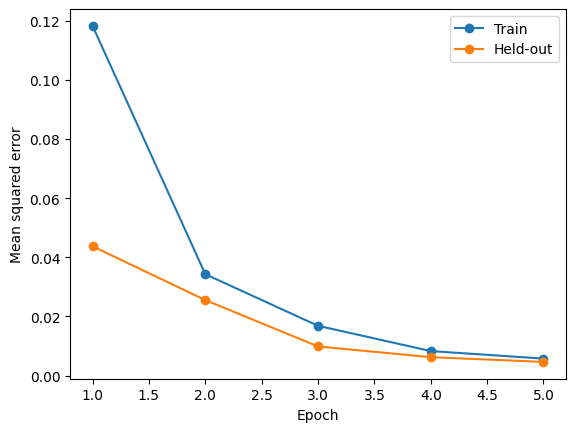

In [8]:
criterion = nn.MSELoss()

@torch.no_grad()
def evaluate(model, loader):
    model.eval()
    total_loss = 0.0
    for images, _ in loader:
        images = images.to(device)
        reconstruction, _ = model(images)
        total_loss += criterion(reconstruction, images).item() * images.size(0)
    return total_loss / len(loader.dataset)

# Re-running this cell starts a fresh model and optimizer.
torch.manual_seed(42)
model = ImageEncoderDecoder(LATENT_CHANNELS).to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
initial_mse = evaluate(model, test_loader)
print(f"Untrained held-out MSE: {initial_mse:.5f}")
history = {"train": [], "test": []}
for epoch in range(EPOCHS):
    model.train()
    total_loss = 0.0
    for images, _ in train_loader:
        images = images.to(device)
        total_loss += train_step(model, images, optimizer, criterion) * images.size(0)
    history["train"].append(total_loss / len(train_loader.dataset))
    history["test"].append(evaluate(model, test_loader))
    print(f"Epoch {epoch + 1}: train MSE={history['train'][-1]:.5f}, "
          f"held-out MSE={history['test'][-1]:.5f}")

plt.plot(range(1, EPOCHS + 1), history["train"], marker="o", label="Train")
plt.plot(range(1, EPOCHS + 1), history["test"], marker="o", label="Held-out")
plt.xlabel("Epoch")
plt.ylabel("Mean squared error")
plt.legend()
plt.show()

## 5. Inspect the reconstruction and latent (10 minutes)
Look for digit identity, stroke thickness, and missing detail. A low average pixel error alone does not guarantee sharp or useful images. Feature maps are learned activations, not necessarily human-readable parts of a digit.

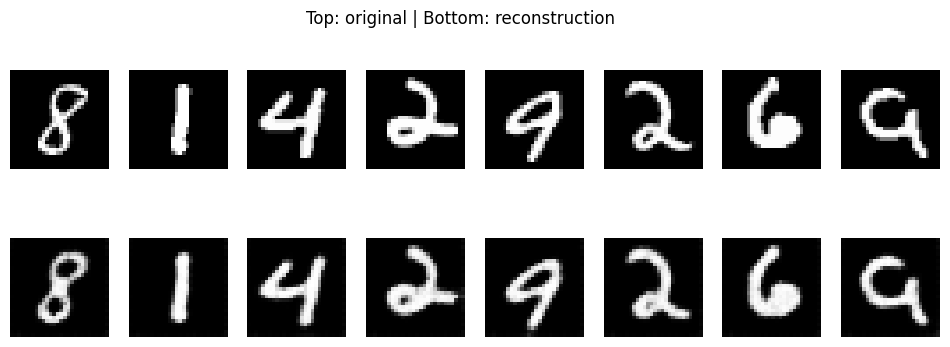

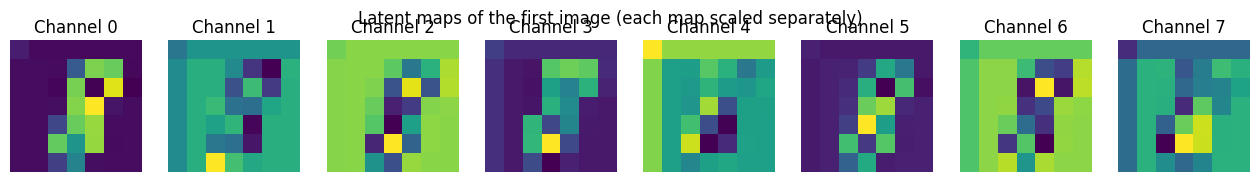

In [9]:
model.eval()
examples, _ = next(iter(test_loader))
with torch.no_grad():
    reconstructed, latents = model(examples[:8].to(device))
reconstructed, latents = reconstructed.cpu(), latents.cpu()
fig, axes = plt.subplots(2, 8, figsize=(12, 4))
for i in range(8):
    axes[0, i].imshow(examples[i, 0], cmap="gray", vmin=0, vmax=1)
    axes[1, i].imshow(reconstructed[i, 0], cmap="gray", vmin=0, vmax=1)
    axes[0, i].axis("off")
    axes[1, i].axis("off")
fig.suptitle("Top: original | Bottom: reconstruction")
plt.show()

count = min(LATENT_CHANNELS, 8)
fig, axes = plt.subplots(1, count, figsize=(2 * count, 2), squeeze=False)
for i in range(count):
    axes[0, i].imshow(latents[0, i], cmap="viridis")
    axes[0, i].set_title(f"Channel {i}")
    axes[0, i].axis("off")
fig.suptitle("Latent maps of the first image (each map scaled separately)")
plt.show()

## 6. Experiment with the bottleneck (10–15 minutes)
Run the lab with `LATENT_CHANNELS = 2`, `8`, and `32`. Change the value in the setup cell and rerun from that cell downward. Keep the data, seed, learning rate, and epoch count fixed. The training cell creates a fresh model each time. Save your observations before the next run.

| Latent channels | Values per image | Input/latent ratio | Final train MSE | Final held-out MSE | Visible differences |
|---|---|---|---|---|---|
| 2 | 98 | 8.0 | 0.01208 | 0.01065 | Digits still readable but blurry and blotchy; the 8's loops smear together, strokes of 2 and 6 get thick and filled-in |
| 8 | 392 | 2.0 | 0.00571 | 0.00466 | All digits clearly recognizable; slight blur/thickening on thin strokes (e.g. tail of the 2) |
| 32 | 1568 | 0.5 | 0.00371 | 0.00314 | Sharpest, closest to the originals; loops of 8 and 2 are clean, only minor edge softening |

(5 epochs, 5000 train / 1000 held-out images, seed 42, Adam lr=1e-3. Numbers and images come from the experiment cell below.)

This is an exploratory comparison: changing channels also changes the parameter count. Small runs may not show a consistent ranking. Since we repeatedly inspect this held-out subset, treat it as validation data rather than an untouched final benchmark.

**Discuss:**
1. **Yes.** Held-out MSE fell from 0.01065 (L=2) → 0.00466 (L=8) → 0.00314 (L=32), and in the comparison figure the L=2 digits are blotchy (the 8 smears) while L=32 is nearly identical to the originals. The gain from 2→8 is much larger than 8→32 (diminishing returns). Part of the gain also comes from the extra parameters, not only from latent size.
2. Downsampling only shrinks H×W; the channel count can grow. Compression depends on total values C×H×W. At L=32 the 7×7 latent holds 1568 values vs 784 in the input — smaller grid, but *more* numbers.
3. Transposed convolutions only produce an output of the right shape; the content must come from the latent. When the bottleneck has fewer values than the input (L=2, L=8), information is lost, and the decoder (trained with MSE) outputs an average-looking, blurry guess for the missing detail.
4. A `[N, 128]` vector is flattened: it has no spatial grid, so the location of features must be encoded implicitly and decoded via linear/reshape layers. Our `[N, L, 7, 7]` latent keeps "where" explicitly — each 7×7 position describes a local region — which preserves spatial structure and uses convolutions only.
5. A skip connection could carry the 14×14 encoder features (after Encoder 1) directly to the 14×14 decoder stage (as in U-Net). That gives the decoder high-resolution detail that bypasses the bottleneck, so the network can reconstruct well even with a tiny latent — the bottleneck no longer forces compression, and the latent may learn little.
6. The model was only trained to map real images to latents and back. Nothing constrains the latent space to follow a known distribution, so random latents (e.g. `torch.randn`) land in regions the decoder never saw and usually decode to noise/blobs. Reliable generation needs a structured latent (e.g. a VAE with a prior) or another generative model.

L= 2: values=  98, ratio=8.00, train MSE=0.01208, held-out MSE=0.01065


L= 8: values= 392, ratio=2.00, train MSE=0.00571, held-out MSE=0.00466


L=32: values=1568, ratio=0.50, train MSE=0.00371, held-out MSE=0.00314


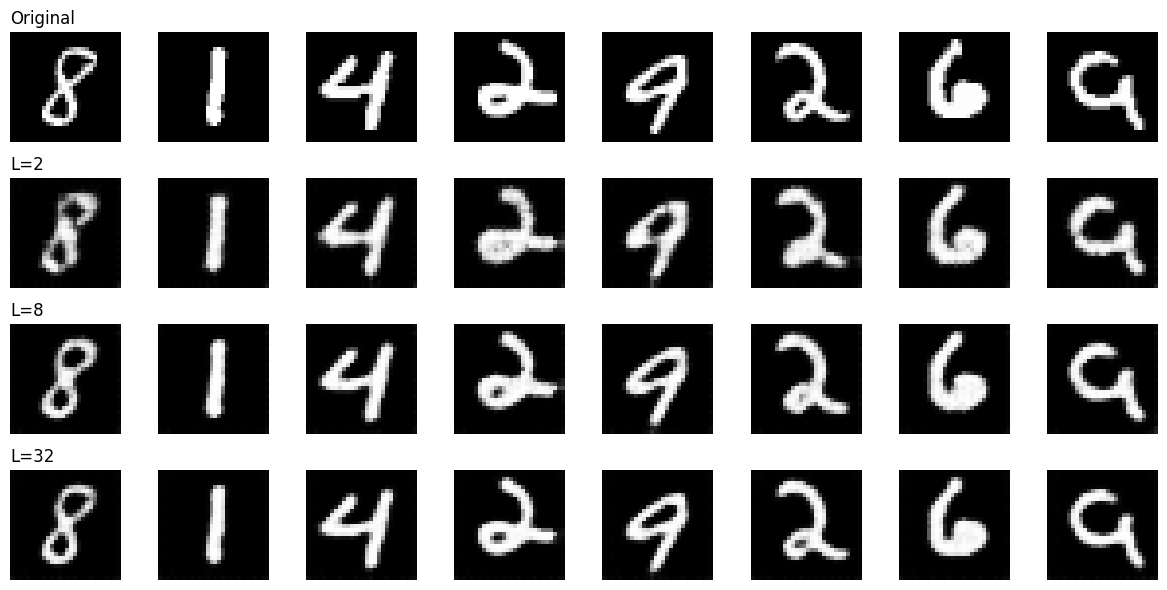

In [10]:
# Section 6 experiment: a fresh model per latent size, same seed/data/lr/epochs.
def train_model(latent_channels, noise=0.0):
    torch.manual_seed(42)
    m = ImageEncoderDecoder(latent_channels).to(device)
    opt = torch.optim.Adam(m.parameters(), lr=1e-3)
    for _ in range(EPOCHS):
        m.train()
        total = 0.0
        for x, _ in train_loader:
            x = x.to(device)
            noisy = (x + noise * torch.randn_like(x)).clamp(0, 1)
            opt.zero_grad()
            loss = criterion(m(noisy)[0], x)  # clean image is always the target
            loss.backward()
            opt.step()
            total += loss.item() * x.size(0)
    return m, total / len(train_loader.dataset)

fig, axes = plt.subplots(4, 8, figsize=(12, 6))
for i in range(8):
    axes[0, i].imshow(examples[i, 0], cmap="gray", vmin=0, vmax=1)
axes[0, 0].set_title("Original", loc="left")
for row, L in enumerate([2, 8, 32], start=1):
    m, train_mse = train_model(L)
    print(f"L={L:2d}: values={L*49:4d}, ratio={784/(L*49):.2f}, "
          f"train MSE={train_mse:.5f}, held-out MSE={evaluate(m, test_loader):.5f}")
    with torch.no_grad():
        rec = m(examples[:8].to(device))[0].cpu()
    for i in range(8):
        axes[row, i].imshow(rec[i, 0], cmap="gray", vmin=0, vmax=1)
    axes[row, 0].set_title(f"L={L}", loc="left")
for ax in axes.flat:
    ax.axis("off")
plt.tight_layout()
plt.show()

## Optional extension: denoising
Keep the architecture and start with a fresh model and optimizer. Add noise to the training **input**, while retaining the clean image as the **target**:

```python
noisy = (images + 0.3 * torch.randn_like(images)).clamp(0, 1)
reconstruction, _ = model(noisy)
loss = criterion(reconstruction, images)
```

Update both training and evaluation to use noisy inputs and clean targets. For evaluation, generate one fixed set of noisy held-out images and reuse it. Compare noisy-input MSE with denoised-output MSE against the clean images, and plot clean/noisy/reconstructed rows. Merely feeding noise to a reconstruction-trained model is not the same as training a denoiser.

An alternative extension is to replace each transposed convolution with 2× bilinear upsampling (`align_corners=False`) followed by a 3×3 convolution with padding 1. Keep the intermediate ReLU and final Sigmoid and check shapes before retraining.

Noisy-input MSE:     0.04659
Denoised-output MSE: 0.01068


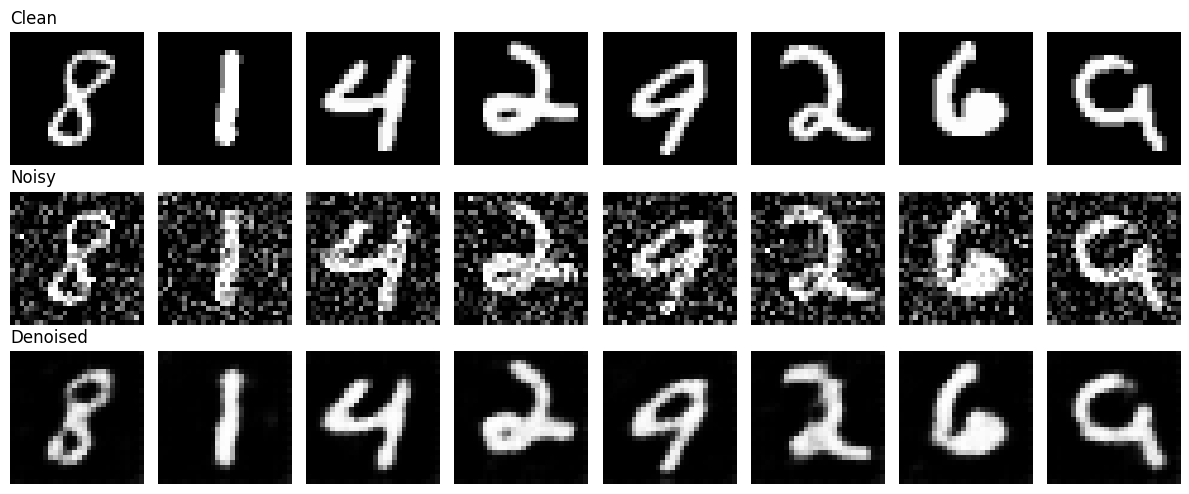

In [11]:
# Denoising: train on noisy inputs with clean targets; evaluate on one fixed noisy test set.
denoiser, _ = train_model(LATENT_CHANNELS, noise=0.3)
denoiser.eval()
torch.manual_seed(0)
clean = torch.cat([x for x, _ in test_loader]).to(device)
noisy = (clean + 0.3 * torch.randn_like(clean)).clamp(0, 1)  # fixed, reused
with torch.no_grad():
    denoised = denoiser(noisy)[0]
print(f"Noisy-input MSE:     {criterion(noisy, clean).item():.5f}")
print(f"Denoised-output MSE: {criterion(denoised, clean).item():.5f}")

fig, axes = plt.subplots(3, 8, figsize=(12, 5))
for row, (name, imgs) in enumerate([("Clean", clean), ("Noisy", noisy), ("Denoised", denoised)]):
    for i in range(8):
        axes[row, i].imshow(imgs[i, 0].cpu(), cmap="gray", vmin=0, vmax=1)
        axes[row, i].axis("off")
    axes[row, 0].set_title(name, loc="left")
plt.tight_layout()
plt.show()

**Denoising result (L=8, noise σ=0.3):** noisy-input MSE = 0.04659 vs denoised-output MSE = 0.01068, about a 4.4× reduction. The denoised digits are clean and recognizable with the background noise removed, though strokes are a bit thicker and blurrier than the clean images.

## Submission and assessment
Submit the completed notebook with:
- all four TODOs implemented and shape checks passing (**4 marks**);
- your completed shape table and latent-size calculations (**2 marks**);
- training curves and original/reconstructed images (**2 marks**);
- the three-run experiment table and evidence-based discussion (**2 marks**).

Expected behavior: reconstruction error should generally decrease and reconstructed digits should become recognizable, though some strokes may remain blurred. No fixed MSE threshold is required. If training fails, check the target, output range, gradient update, and tensor shapes before increasing epochs.